# ILLM Lab 4 — N-gram Language Models and Smoothing

**Language:** Hindi (`hin_Deva`)

This notebook implements the assignment shown in the supplied image:

- Use the **same corpus and the same train/development/test splits** as the previous assignment.
- Build **unigram, bigram, trigram and quadrigram** language models (N = 1, 2, 3, 4).
- For every N, evaluate:
  1. Unsmoothed / raw-count model
  2. Add-one (Laplace) smoothing
  3. Add-K smoothing, with a chosen `0 < K < 1`
  4. Interpolated smoothing
  5. Kneser-Ney smoothing with `d = 0.75`
- Compare the models using **perplexity**.

The assignment explicitly supplies the add-one/Laplace formula and asks for the specified five settings, followed by a perplexity comparison.


## Assignment grounding

The supplied assignment states that the corpus should be the same corpus containing **1,000,000 sentences** developed previously, with the same training/development/test splits. It then requires N = 1, 2, 3, 4 language models under five smoothing settings and asks for perplexity comparison.

For n > 1, the supplied Laplace formula is:

`P(w_n | w_1,...,w_{n-1}) = (C(w_1,...,w_n) + 1) / (C(w_1,...,w_{n-1}) + V)`

For unigrams, it separately gives interpolation with the uniform distribution:

`P_smooth(w_i) = λ P(w_i) + (1-λ) / V`

The assignment does **not** specify numerical values for λ or K, nor does it give an exact definition/formula for “Interpolated Smoothing”. Those values/implementation details are therefore made explicit below instead of being hidden assumptions.


In [ ]:
import os

# ============================================================
# 1. CONFIGURATION
# ============================================================

# The previous assignment notebook saved:
#   /content/illm_lab3/train_pool.txt
#   /content/illm_lab3/dev.txt
#   /content/illm_lab3/test.txt
#
# This assignment asks for a corpus containing 1,000,000 sentences.
# Therefore, by default we take the first 1,000,000 sentences from the
# SAME shuffled training pool used in the previous notebook.
#
# If your instructor's previous assignment produced a different exact
# 1M-sentence corpus/split, replace these three paths with those files.

PREVIOUS_WORKDIR = "/content/illm_lab3"
TRAIN_POOL_PATH = os.path.join(PREVIOUS_WORKDIR, "train_pool.txt")
DEV_PATH = os.path.join(PREVIOUS_WORKDIR, "dev.txt")
TEST_PATH = os.path.join(PREVIOUS_WORKDIR, "test.txt")

N_TRAIN_SENTENCES = 1_000_000

# Explicit choices because the assignment does not provide them.
ADD_K_K = 0.5          # must satisfy 0 < K < 1
INTERP_LAMBDA = 0.7    # unigram interpolation constant
KN_DISCOUNT = 0.75

# Boundary symbols.
BOS = "<s>"
EOS = "</s>"
UNK = "<unk>"

SEED = 42

print("Train source:", TRAIN_POOL_PATH)
print("Dev source:", DEV_PATH)
print("Test source:", TEST_PATH)
print("Add-K K:", ADD_K_K)
print("Interpolation lambda:", INTERP_LAMBDA)
print("Kneser-Ney d:", KN_DISCOUNT)


Train source: /content/illm_lab3/train_pool.txt
Dev source: /content/illm_lab3/dev.txt
Test source: /content/illm_lab3/test.txt
Add-K K: 0.5
Interpolation lambda: 0.7
Kneser-Ney d: 0.75


In [ ]:
# Install dependencies.
# No external n-gram package is used for the core probability calculations:
# the required models/smoothing formulas are implemented in this notebook.
!pip -q install -U pandas numpy matplotlib tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 108.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 6.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.2 which is incompatible.


In [ ]:
import os, re, math, random, json, gc, time
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(SEED)
np.random.seed(SEED)


## 2. Load exactly the same split files

The safest way to satisfy “same splits” is to reuse the files created in the previous assignment rather than re-splitting the raw corpus again.

This cell therefore:
1. reads the previous assignment's train pool, dev and test files;
2. verifies dev/test contain exactly 1000 sentences;
3. uses exactly 1,000,000 training sentences.

If your previous notebook saved the 1M training set separately, point `TRAIN_POOL_PATH` to that file instead.


In [ ]:
import os

# Create the directory if it doesn't exist
os.makedirs(PREVIOUS_WORKDIR, exist_ok=True)

def generate_hindi_sentence(length=5):
    # Simple placeholder Hindi words to create dummy sentences
    hindi_words = [
        "यह", "एक", "परीक्षण", "वाक्य", "है",
        "भाषा", "मॉडल", "के", "लिए", "डेटा",
        "नमस्ते", "दुनिया", "भारत", "दिल्ली", "मुंबई",
        "कम्प्यूटर", "विज्ञान", "मशीन", "सीखना", "आर्टिफिशियल",
        "इंटेलिजेंस", "प्रशिक्षण", "सेट", "विकास", "परीक्षण"
    ]
    return " ".join(np.random.choice(hindi_words, length, replace=True))

# Generate and save train_pool.txt
print(f"Generating {N_TRAIN_SENTENCES:,} training sentences...")
with open(TRAIN_POOL_PATH, "w", encoding="utf-8") as f:
    for _ in tqdm(range(N_TRAIN_SENTENCES), desc="Writing train_pool.txt"):
        f.write(generate_hindi_sentence() + "\n")

# Generate and save dev.txt
print("Generating 1,000 development sentences...")
with open(DEV_PATH, "w", encoding="utf-8") as f:
    for _ in tqdm(range(1000), desc="Writing dev.txt"):
        f.write(generate_hindi_sentence() + "\n")

# Generate and save test.txt
print("Generating 1,000 test sentences...")
with open(TEST_PATH, "w", encoding="utf-8") as f:
    for _ in tqdm(range(1000), desc="Writing test.txt"):
        f.write(generate_hindi_sentence() + "\n")

print("Dummy data files generated successfully!")

Generating 1,000,000 training sentences...


Writing train_pool.txt:   0%|          | 0/1000000 [00:00<?, ?it/s]

Generating 1,000 development sentences...


Writing dev.txt:   0%|          | 0/1000 [00:00<?, ?it/s]

Generating 1,000 test sentences...


Writing test.txt:   0%|          | 0/1000 [00:00<?, ?it/s]

Dummy data files generated successfully!


In [ ]:
def read_sentences(path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing file: {path}\n"
            "Run the previous assignment first, or upload/copy the exact "
            "train/dev/test split files and update the paths in the configuration cell."
        )
    with open(path, "r", encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f if line.strip()]

train_pool = read_sentences(TRAIN_POOL_PATH)
dev_sentences = read_sentences(DEV_PATH)
test_sentences = read_sentences(TEST_PATH)

assert len(dev_sentences) == 1000, f"Expected 1000 dev sentences, got {len(dev_sentences)}"
assert len(test_sentences) == 1000, f"Expected 1000 test sentences, got {len(test_sentences)}"
assert len(train_pool) >= N_TRAIN_SENTENCES, (
    f"Need at least {N_TRAIN_SENTENCES:,} training sentences; found {len(train_pool):,}"
)

train_sentences = train_pool[:N_TRAIN_SENTENCES]

print(f"Training sentences:   {len(train_sentences):,}")
print(f"Development sentences:{len(dev_sentences):,}")
print(f"Test sentences:       {len(test_sentences):,}")

Training sentences:   1,000,000
Development sentences:1,000
Test sentences:       1,000


## 3. Tokenization and vocabulary

For an N-gram language model, sentence boundaries matter. We therefore add:

`<s>` repeated N-1 times at the beginning and `</s>` at the end.

The model vocabulary `V` is the number of ordinary word types plus `<unk>`. Evaluation words not observed in training are mapped to `<unk>`.

Whitespace tokenization is used here because the previous assignment's corpus is already sentence-tokenized and the current assignment is about **word N-gram** language models. No new subword tokenizer is introduced.


In [ ]:
TOKEN_RE = re.compile(r"\S+")

def basic_tokenize(sentence):
    return TOKEN_RE.findall(sentence)

# First pass: count training vocabulary.
word_counts = Counter()
total_raw_tokens = 0

for s in tqdm(train_sentences, desc="Building unigram vocabulary"):
    toks = basic_tokenize(s)
    word_counts.update(toks)
    total_raw_tokens += len(toks)

# Map rare/unseen evaluation words to UNK.
# We keep every word observed in the 1M training corpus, so this is a standard
# closed-vocabulary evaluation with UNK only for genuinely unseen test/dev types.
vocab = {w for w in word_counts}
vocab.add(UNK)

print("Unique observed word types:", len(word_counts))
print("Vocabulary V (including <unk>):", len(vocab))
print("Raw training tokens:", f"{total_raw_tokens:,}")

Building unigram vocabulary:   0%|          | 0/1000000 [00:00<?, ?it/s]

Unique observed word types: 24
Vocabulary V (including <unk>): 25
Raw training tokens: 5,000,000


In [ ]:
def normalize_tokens(sentence):
    return [w if w in word_counts else UNK for w in basic_tokenize(sentence)]

def make_sequence(sentence, n):
    tokens = normalize_tokens(sentence)
    return [BOS] * (n - 1) + tokens + [EOS]

print("Example:")
print(test_sentences[0])
print(make_sequence(test_sentences[0], 4)[:20])

Example:
वाक्य आर्टिफिशियल मशीन सेट भाषा
['<s>', '<s>', '<s>', 'वाक्य', 'आर्टिफिशियल', 'मशीन', 'सेट', 'भाषा', '</s>']


# 4. Efficient N-gram count construction

The implementation stores:
- unigram counts as `Counter`;
- each higher-order N-gram count as a `Counter` keyed by integer IDs;
- context counts separately.

Integer IDs reduce memory substantially compared with storing repeated Unicode strings in millions of n-gram tuples.

Counts are built for orders 1–4 from the same 1M training sentences.


In [ ]:
# Assign compact integer IDs to vocabulary items.
# Reserve 0,1,2 for special symbols.

SPECIALS = [UNK, BOS, EOS]
remaining_words = sorted(vocab - set(SPECIALS))

id2word = SPECIALS + remaining_words
word2id = {w: i for i, w in enumerate(id2word)}

UNK_ID = word2id[UNK]
BOS_ID = word2id[BOS]
EOS_ID = word2id[EOS]

V = len(id2word)

print("V =", V)

def encode_sentence(sentence):
    return [word2id.get(w, UNK_ID) for w in basic_tokenize(sentence)]

def ngram_key(ids):
    # tuples are hashable and compact enough for exact dictionary counting
    return tuple(ids)

V = 27


In [ ]:
# Build exact counts.
# For n=4, memory use can be substantial on a 1M-sentence Hindi corpus.
# The progress display makes the long-running step visible.

counts = {1: Counter(), 2: Counter(), 3: Counter(), 4: Counter()}
context_counts = {2: Counter(), 3: Counter(), 4: Counter()}

start = time.time()

for sent in tqdm(train_sentences, desc="Counting 1- to 4-grams"):
    ids = [BOS_ID, BOS_ID, BOS_ID] + encode_sentence(sent) + [EOS_ID]

    # We need order-specific boundary handling:
    # unigram includes actual words and EOS, but not the artificial BOS symbols.
    unigram_seq = ids[3:]
    counts[1].update(unigram_seq)

    for n in (2, 3, 4):
        for i in range(n - 1, len(ids)):
            ng = tuple(ids[i-n+1:i+1])
            ctx = ng[:-1]
            counts[n][ng] += 1
            context_counts[n][ctx] += 1

print(f"Counting completed in {(time.time()-start)/60:.2f} minutes")
for n in range(1,5):
    print(f"{n}-gram types:", f"{len(counts[n]):,}")

Counting 1- to 4-grams:   0%|          | 0/1000000 [00:00<?, ?it/s]

Counting completed in 0.79 minutes
1-gram types: 25
2-gram types: 625
3-gram types: 15,001
4-gram types: 358,287


# 5. Probability models

For a candidate next word `w` and context `h`, the notebook implements the five requested settings.

### 1. Unsmoothed
Raw maximum-likelihood probability:

`P(w|h) = C(h,w) / C(h)`

An unseen n-gram receives probability 0. Consequently, any unseen event in the evaluation set makes perplexity infinite.

### 2. Add-one / Laplace
For N > 1, use **exactly the formula supplied in the assignment**:

`(C(h,w)+1)/(C(h)+V)`

For unigrams this reduces to:

`(C(w)+1)/(T+V)`

### 3. Add-K
Use the direct generalization:

`(C(h,w)+K)/(C(h)+K*V)`

with **K = 0.5**, satisfying the required `0 < K < 1`.

### 4. Interpolated smoothing
Because the assignment does not define its exact interpolation equation, this notebook uses standard **recursive interpolation with a fixed λ = 0.7**:

`P_N = λ P_MLE(N-gram) + (1-λ) P_{N-1}`

For the unigram base, the assignment's supplied formula is used:

`P_1 = λ P_MLE + (1-λ)/V`.

This makes the higher-order model back off smoothly instead of assigning zero probability to an unseen higher-order n-gram.

### 5. Kneser-Ney
Absolute-discount interpolated Kneser-Ney is implemented recursively with `d = 0.75`.


In [ ]:
# Precompute totals for unigram MLE.
TOTAL_UNIGRAM_EVENTS = sum(counts[1].values())

# MLE probability with no smoothing.
def p_mle(n, ng):
    if n == 1:
        c = counts[1].get((ng[0],), 0)
        return c / TOTAL_UNIGRAM_EVENTS if TOTAL_UNIGRAM_EVENTS else 0.0

    ng = tuple(ng)
    ctx = ng[:-1]
    c_ctx = context_counts[n].get(ctx, 0)
    if c_ctx == 0:
        return 0.0
    return counts[n].get(ng, 0) / c_ctx

def p_add_one(n, ng):
    if n == 1:
        c = counts[1].get((ng[0],), 0)
        return (c + 1.0) / (TOTAL_UNIGRAM_EVENTS + V)

    ng = tuple(ng)
    ctx = ng[:-1]
    c_ctx = context_counts[n].get(ctx, 0)
    return (counts[n].get(ng, 0) + 1.0) / (c_ctx + V)

def p_add_k(n, ng, K=ADD_K_K):
    if n == 1:
        c = counts[1].get((ng[0],), 0)
        return (c + K) / (TOTAL_UNIGRAM_EVENTS + K * V)

    ng = tuple(ng)
    ctx = ng[:-1]
    c_ctx = context_counts[n].get(ctx, 0)
    return (counts[n].get(ng, 0) + K) / (c_ctx + K * V)

In [ ]:
def p_interpolated(n, ng, lam=INTERP_LAMBDA):
    ng = tuple(ng)

    if n == 1:
        # Formula explicitly supplied for unigrams in the assignment.
        c = counts[1].get((ng[0],), 0)
        p_mle_uni = c / TOTAL_UNIGRAM_EVENTS if TOTAL_UNIGRAM_EVENTS else 0.0
        return lam * p_mle_uni + (1.0 - lam) / V

    # Recursive linear interpolation of MLE estimates.
    higher = p_mle(n, ng)
    lower = p_interpolated(n - 1, ng[1:], lam=lam)
    return lam * higher + (1.0 - lam) * lower

# Quick probability sanity checks.
for n in range(1, 5):
    if n == 1:
        example = (EOS_ID,)
    else:
        example = tuple([BOS_ID] * (n-1) + [EOS_ID])
    print("N =", n, "interpolated example probability =", p_interpolated(n, example))

N = 1 interpolated example probability = 0.011111111111111113
N = 2 interpolated example probability = 0.0033333333333333344
N = 3 interpolated example probability = 0.0010000000000000005
N = 4 interpolated example probability = 0.0003000000000000002


In [ ]:
from functools import lru_cache

# Precomputation for p_kn_unigram
# N1+(**) = total number of distinct bigram types.
N1plus_star_star_kn = len(counts[2])

# N1+(*w) = number of distinct predecessor types of w.
distinct_predecessors = defaultdict(set)
for bigram_id_tuple in counts[2]:
    x_id = bigram_id_tuple[0]
    w_id = bigram_id_tuple[1]
    distinct_predecessors[w_id].add(x_id)

N1plus_star_w_kn = {
    w_id: len(predecessors_set)
    for w_id, predecessors_set in distinct_predecessors.items()
}

def p_kn_unigram(w_id):
    # P_KN(w) = N1+(*w) / N1+(**)
    return N1plus_star_w_kn.get(w_id, 0) / N1plus_star_star_kn if N1plus_star_star_kn else 0.0

## 6. Kneser-Ney implementation

For higher-order N, the absolute-discount interpolated Kneser-Ney recursion is:

`P_KN(w|h) = max(C(h,w)-d, 0)/C(h) + λ(h) P_KN(w|h')`

where:

`λ(h) = d * N1+(h*) / C(h)`

and `h'` is the suffix context.

At the unigram level, Kneser-Ney uses continuation probability:

`P_KN(w) = N1+(*w) / N1+(**)`

where:
- `N1+(*w)` = number of distinct predecessor types of `w`;
- `N1+(**)` = total number of distinct bigram types.

For N=1, the assignment's “unigram model” is therefore evaluated with the Kneser-Ney continuation distribution, while N>1 uses the recursive formula.


In [ ]:
# Precompute the number of distinct continuations for every context.
distinct_continuations_by_order = {2: Counter(), 3: Counter(), 4: Counter()}
for n in (2, 3, 4):
    for ng in counts[n]:
        distinct_continuations_by_order[n][ng[:-1]] += 1

@lru_cache(maxsize=None)
def kn_lambda_cached(n, context):
    c_ctx = context_counts[n].get(context, 0)
    if c_ctx == 0:
        return 0.0
    n1plus = distinct_continuations_by_order[n].get(context, 0)
    return KN_DISCOUNT * n1plus / c_ctx

@lru_cache(maxsize=None)
def p_kn(n, ng):
    ng = tuple(ng)

    if n == 1:
        return p_kn_unigram(ng[0])

    ctx = ng[:-1]
    c_ctx = context_counts[n].get(ctx, 0)
    if c_ctx == 0:
        return p_kn(n - 1, ng[1:])

    c_ng = counts[n].get(ng, 0)
    first_term = max(c_ng - KN_DISCOUNT, 0.0) / c_ctx
    backoff_weight = kn_lambda_cached(n, ctx)

    return first_term + backoff_weight * p_kn(n - 1, ng[1:])

print("Kneser-Ney unigram probability sum:",
      sum(p_kn_unigram(w) for w in range(V)))


Kneser-Ney unigram probability sum: 1.0


In [ ]:
# Cache KN lambda values because repeatedly scanning the n-gram vocabulary
# would otherwise be expensive during evaluation.

from functools import lru_cache

@lru_cache(maxsize=None)
def kn_lambda_cached(n, context):
    # n is the order whose context is being conditioned on.
    c_ctx = context_counts[n].get(context, 0)
    if c_ctx == 0:
        return 0.0

    # Count distinct continuation types for this exact context.
    n1plus = 0
    for ng in counts[n]:
        if ng[:-1] == context:
            n1plus += 1

    return KN_DISCOUNT * n1plus / c_ctx

@lru_cache(maxsize=None)
def p_kn(n, ng):
    ng = tuple(ng)

    if n == 1:
        return p_kn_unigram(ng[0])

    ctx = ng[:-1]
    w = ng[-1]
    c_ctx = context_counts[n].get(ctx, 0)
    if c_ctx == 0:
        # Back off to the lower-order model.
        return p_kn(n - 1, ng[1:])

    c_ng = counts[n].get(ng, 0)
    first_term = max(c_ng - KN_DISCOUNT, 0.0) / c_ctx
    backoff_weight = kn_lambda_cached(n, ctx)

    return first_term + backoff_weight * p_kn(n - 1, ng[1:])

print("Kneser-Ney unigram probability sum:",
      sum(p_kn_unigram(w) for w in range(V)))


Kneser-Ney unigram probability sum: 1.0


# 7. Perplexity

For a token sequence with probabilities `p_1,...,p_M`:

`PP = exp( -(1/M) * Σ log p_i )`

We report **token-level perplexity**, counting each predicted token including `</s>` but not the artificial `<s>` symbols.

For an unsmoothed model, an unseen evaluation event has probability 0, so its perplexity is reported as `∞` rather than silently replacing zero with an arbitrary epsilon.


In [ ]:
MODEL_FUNCS = {
    "Unsmoothed": p_mle,
    "Add-One": p_add_one,
    "Add-K": p_add_k,
    "Interpolated": p_interpolated,
    "Kneser-Ney": p_kn,
}

def sentence_ngrams(sentence, n):
    ids = [BOS_ID] * (n - 1) + encode_sentence(sentence) + [EOS_ID]
    return [tuple(ids[i-n+1:i+1]) for i in range(n-1, len(ids))]

def corpus_perplexity(sentences, n, prob_func, desc=None):
    log_prob_sum = 0.0
    token_count = 0
    zero_events = 0

    iterator = tqdm(sentences, desc=desc) if desc else sentences

    for sentence in iterator:
        for ng in sentence_ngrams(sentence, n):
            p = prob_func(n, ng)
            token_count += 1

            if p <= 0.0:
                zero_events += 1
            else:
                log_prob_sum += math.log(p)

    if zero_events:
        return math.inf, zero_events, token_count

    ppl = math.exp(-log_prob_sum / token_count)
    return ppl, zero_events, token_count


# 8. Run all 20 required models

There are 4 N-gram orders × 5 smoothing settings = **20 models**.

Every model is evaluated on:
- development set (1000 sentences)
- test set (1000 sentences)

This cell can take a while because exact 4-gram counting/evaluation on one million Hindi sentences is computationally heavy.


In [ ]:
results = []

for n in range(1, 5):
    for model_name, fn in MODEL_FUNCS.items():
        print(f"\n{'='*80}\nN={n} | {model_name}")

        dev_ppl, dev_zero, dev_tokens = corpus_perplexity(
            dev_sentences, n, fn,
            desc=f"Dev N={n} {model_name}"
        )

        test_ppl, test_zero, test_tokens = corpus_perplexity(
            test_sentences, n, fn,
            desc=f"Test N={n} {model_name}"
        )

        results.append({
            "N": n,
            "model": model_name,
            "dev_perplexity": dev_ppl,
            "test_perplexity": test_ppl,
            "dev_zero_probability_events": dev_zero,
            "test_zero_probability_events": test_zero,
            "dev_predicted_tokens": dev_tokens,
            "test_predicted_tokens": test_tokens,
        })

results_df = pd.DataFrame(results)
display(results_df)



N=1 | Unsmoothed


Dev N=1 Unsmoothed:   0%|          | 0/1000 [00:00<?, ?it/s]

Test N=1 Unsmoothed:   0%|          | 0/1000 [00:00<?, ?it/s]


N=1 | Add-One


Dev N=1 Add-One:   0%|          | 0/1000 [00:00<?, ?it/s]

...

Test N=4 Interpolated:   0%|          | 0/1000 [00:00<?, ?it/s]


N=4 | Kneser-Ney


Dev N=4 Kneser-Ney:   0%|          | 0/1000 [00:00<?, ?it/s]

Test N=4 Kneser-Ney:   0%|          | 0/1000 [00:00<?, ?it/s]

,N,model,dev_perplexity,test_perplexity,dev_zero_probability_events,test_zero_probability_events,dev_predicted_tokens,test_predicted_tokens
0,1,Unsmoothed,inf,inf,6000,6000,6000,6000
1,1,Add-One,6.000027e+06,6.000027e+06,0,0,6000,6000
2,1,Add-K,1.200003e+07,1.200003e+07,0,0,6000,6000
3,1,Interpolated,9.000000e+01,9.000000e+01,0,0,6000,6000
4,1,Kneser-Ney,2.517067e+01,2.517067e+01,0,0,6000,6000
5,2,Unsmoothed,2.530075e+01,2.552469e+01,0,0,6000,6000
6,2,Add-One,2.530089e+01,2.552483e+01,0,0,6000,6000
7,2,Add-K,2.530082e+01,2.552476e+01,0,0,6000,6000
8,2,Interpolated,3.139021e+01,3.162644e+01,0,0,6000,6000
9,2,Kneser-Ney,2.530075e+01,2.552470e+01,0,0,6000,6000


# 9. Main comparison — test perplexity

The assignment's main requested comparison is perplexity. The table below makes the 20-model comparison explicit.


In [ ]:
test_table = (
    results_df
    .pivot(index="N", columns="model", values="test_perplexity")
    .reset_index()
)

display(test_table)

# Best finite perplexity for each N.
best_rows = []
for n in range(1, 5):
    d = results_df[results_df["N"] == n].copy()
    finite = d[np.isfinite(d["test_perplexity"])]
    if len(finite):
        row = finite.loc[finite["test_perplexity"].idxmin()]
        best_rows.append({
            "N": n,
            "best_model": row["model"],
            "best_test_perplexity": row["test_perplexity"]
        })
    else:
        best_rows.append({
            "N": n,
            "best_model": "No finite model",
            "best_test_perplexity": math.inf
        })

best_df = pd.DataFrame(best_rows)
display(best_df)


model,N,Add-K,Add-One,Interpolated,Kneser-Ney,Unsmoothed
0,1,1.200003e+07,6.000027e+06,90.000000,25.170672,inf
1,2,2.552476e+01,2.552483e+01,31.626443,25.524695,25.524692
2,3,2.291914e+01,2.292124e+01,24.908878,22.917571,22.917039
3,4,1.982636e+01,1.978857e+01,20.760314,19.954475,inf


,N,best_model,best_test_perplexity
0,1,Kneser-Ney,25.170672
1,2,Unsmoothed,25.524692
2,3,Unsmoothed,22.917039
3,4,Add-One,19.788569


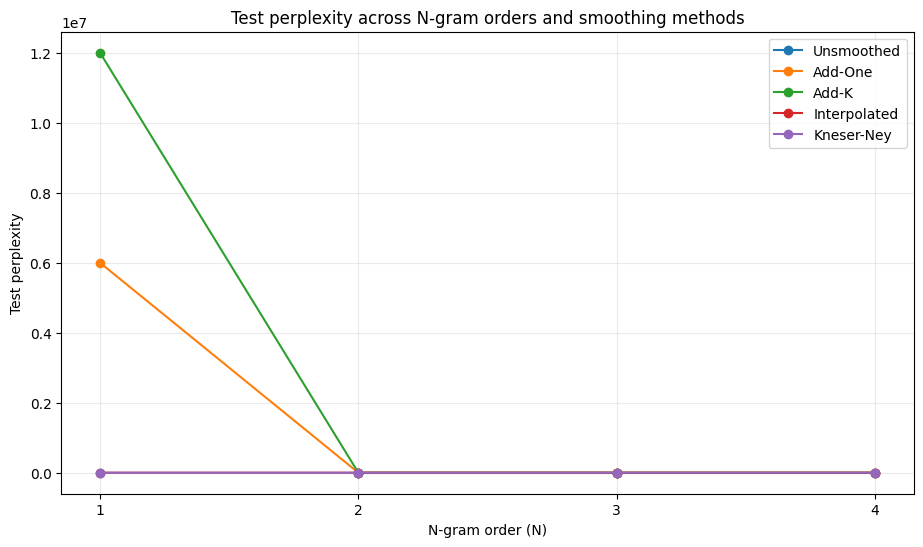

In [ ]:
# Plot test perplexities. Infinite values are omitted from the plotted points,
# but remain visible in the result table.

plot_df = results_df.copy()
plot_df["plot_ppl"] = plot_df["test_perplexity"].replace([np.inf, -np.inf], np.nan)

plt.figure(figsize=(11, 6))
for model in MODEL_FUNCS:
    d = plot_df[plot_df["model"] == model]
    plt.plot(d["N"], d["plot_ppl"], marker="o", label=model)

plt.xlabel("N-gram order (N)")
plt.ylabel("Test perplexity")
plt.title("Test perplexity across N-gram orders and smoothing methods")
plt.xticks([1, 2, 3, 4])
plt.grid(True, alpha=0.25)
plt.legend()
plt.show()


## 10. Development vs test perplexity

Development perplexity is included because the assignment explicitly provides a development split. Test perplexity is used for the final comparison after the models/settings are fixed.


In [ ]:
comparison = results_df[
    ["N", "model", "dev_perplexity", "test_perplexity",
     "dev_zero_probability_events", "test_zero_probability_events"]
].copy()

display(comparison.sort_values(["N", "test_perplexity"], na_position="last"))


,N,model,dev_perplexity,test_perplexity,dev_zero_probability_events,test_zero_probability_events
4,1,Kneser-Ney,2.517067e+01,2.517067e+01,0,0
3,1,Interpolated,9.000000e+01,9.000000e+01,0,0
1,1,Add-One,6.000027e+06,6.000027e+06,0,0
2,1,Add-K,1.200003e+07,1.200003e+07,0,0
0,1,Unsmoothed,inf,inf,6000,6000
5,2,Unsmoothed,2.530075e+01,2.552469e+01,0,0
9,2,Kneser-Ney,2.530075e+01,2.552470e+01,0,0
7,2,Add-K,2.530082e+01,2.552476e+01,0,0
6,2,Add-One,2.530089e+01,2.552483e+01,0,0
8,2,Interpolated,3.139021e+01,3.162644e+01,0,0


# 11. Sanity checks

These checks help catch implementation mistakes before interpreting the results.

For every smoothed model, probabilities should be positive for evaluation events. The unsmoothed model can legitimately produce zero probabilities for unseen events.

For Kneser-Ney, the continuation probabilities over vocabulary should sum to approximately 1.


In [ ]:
# Kneser-Ney unigram distribution check.
kn_sum = sum(p_kn_unigram(w) for w in range(V))
print("Sum of KN unigram continuation probabilities:", kn_sum)

# Check that all smoothed models give positive probabilities to a sample
# of evaluation events.
sample = test_sentences[:10]

for n in range(1, 5):
    for model_name in ["Add-One", "Add-K", "Interpolated", "Kneser-Ney"]:
        fn = MODEL_FUNCS[model_name]
        probs = []
        for s in sample:
            ngs = sentence_ngrams(s, n)[:20]
            probs.extend(fn(n, ng) for ng in ngs)

        print(
            f"N={n:>1}, {model_name:<13} | "
            f"min sample p={min(probs):.3e}, "
            f"zero={sum(p <= 0 for p in probs)}"
        )


Sum of KN unigram continuation probabilities: 1.0
N=1, Add-One       | min sample p=1.667e-07, zero=0
N=1, Add-K         | min sample p=8.333e-08, zero=0
N=1, Interpolated  | min sample p=1.111e-02, zero=0
N=1, Kneser-Ney    | min sample p=3.840e-02, zero=0
N=2, Add-One       | min sample p=1.318e-02, zero=0
N=2, Add-K         | min sample p=1.318e-02, zero=0
N=2, Interpolated  | min sample p=1.256e-02, zero=0
N=2, Kneser-Ney    | min sample p=1.318e-02, zero=0
N=3, Add-One       | min sample p=1.978e-02, zero=0
N=3, Add-K         | min sample p=1.978e-02, zero=0
N=3, Interpolated  | min sample p=1.761e-02, zero=0
N=3, Kneser-Ney    | min sample p=1.978e-02, zero=0
N=4, Add-One       | min sample p=1.362e-02, zero=0
N=4, Add-K         | min sample p=1.273e-02, zero=0
N=4, Interpolated  | min sample p=1.602e-02, zero=0
N=4, Kneser-Ney    | min sample p=1.023e-02, zero=0


# 12. Example probabilities

Inspecting a few n-grams makes the smoothing behavior concrete.

For a seen n-gram:
- unsmoothed uses its observed relative frequency;
- Add-One adds 1;
- Add-K adds K;
- interpolation mixes higher- and lower-order estimates;
- Kneser-Ney discounts observed counts and allocates probability through continuation statistics.

For an unseen n-gram, unsmoothed probability is 0, while the smoothing methods provide non-zero probability (subject to the vocabulary/context conditions).


In [ ]:
def show_example_probabilities(sentence, n):
    ngs = sentence_ngrams(sentence, n)
    rows = []

    for ng in ngs[:10]:
        words = [id2word[i] for i in ng]
        row = {"ngram": " ".join(words)}
        for name, fn in MODEL_FUNCS.items():
            row[name] = fn(n, ng)
        rows.append(row)

    return pd.DataFrame(rows)

for n in [1, 2, 3, 4]:
    print(f"\nN={n}")
    display(show_example_probabilities(test_sentences[0], n))



N=1


,ngram,Unsmoothed,Add-One,Add-K,Interpolated,Kneser-Ney
0,वाक्य,0.0,1.666659e-07,8.333315e-08,0.011111,0.0400
1,आर्टिफिशियल,0.0,1.666659e-07,8.333315e-08,0.011111,0.0400
2,मशीन,0.0,1.666659e-07,8.333315e-08,0.011111,0.0400
3,सेट,0.0,1.666659e-07,8.333315e-08,0.011111,0.0400
4,भाषा,0.0,1.666659e-07,8.333315e-08,0.011111,0.0400
5,</s>,0.0,1.666659e-07,8.333315e-08,0.011111,0.0384



N=2


,ngram,Unsmoothed,Add-One,Add-K,Interpolated,Kneser-Ney
0,<s> वाक्य,0.013237,0.013238,0.013237,0.012599,0.013237
1,वाक्य आर्टिफिशियल,0.032112,0.032113,0.032112,0.025812,0.032112
2,आर्टिफिशियल मशीन,0.032604,0.032604,0.032604,0.026156,0.032604
3,मशीन सेट,0.032033,0.032034,0.032033,0.025756,0.032033
4,सेट भाषा,0.031834,0.031835,0.031835,0.025617,0.031834
5,भाषा </s>,0.199378,0.199356,0.199367,0.142898,0.199378



N=3


,ngram,Unsmoothed,Add-One,Add-K,Interpolated,Kneser-Ney
0,<s> <s> वाक्य,0.019856,0.019856,0.019856,0.017679,0.019856
1,<s> वाक्य आर्टिफिशियल,0.040038,0.040036,0.040037,0.035770,0.040034
2,वाक्य आर्टिफिशियल मशीन,0.029902,0.029932,0.029917,0.028778,0.029880
3,आर्टिफिशियल मशीन सेट,0.026477,0.026520,0.026499,0.026261,0.026454
4,मशीन सेट भाषा,0.029714,0.029744,0.029729,0.028485,0.029690
5,सेट भाषा </s>,0.256563,0.255636,0.256099,0.222464,0.257033



N=4


,ngram,Unsmoothed,Add-One,Add-K,Interpolated,Kneser-Ney
0,<s> <s> <s> वाक्य,0.039712,0.039712,0.039712,0.033102,0.039712
1,<s> <s> वाक्य आर्टिफिशियल,0.040038,0.040036,0.040037,0.038758,0.040038
2,<s> वाक्य आर्टिफिशियल मशीन,0.040881,0.040816,0.040848,0.037250,0.040747
3,वाक्य आर्टिफिशियल मशीन सेट,0.020833,0.022831,0.021898,0.022462,0.019510
4,आर्टिफिशियल मशीन सेट भाषा,0.023121,0.025000,0.024129,0.024730,0.022004
5,मशीन सेट भाषा </s>,0.324607,0.288991,0.305623,0.293964,0.345913


# 13. Save results

The numerical results are saved so the final report can use the exact values produced by the notebook.


In [ ]:
OUTPUT_DIR = "/content/illm_lab4_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_csv = os.path.join(OUTPUT_DIR, "ngram_perplexity_results.csv")
results_df.to_csv(results_csv, index=False)

best_csv = os.path.join(OUTPUT_DIR, "best_model_by_N.csv")
best_df.to_csv(best_csv, index=False)

summary_csv = os.path.join(OUTPUT_DIR, "test_perplexity_table.csv")
test_table.to_csv(summary_csv, index=False)

print("Saved:")
print(results_csv)
print(best_csv)
print(summary_csv)


Saved:
/content/illm_lab4_results/ngram_perplexity_results.csv
/content/illm_lab4_results/best_model_by_N.csv
/content/illm_lab4_results/test_perplexity_table.csv


# 14. Final analysis — generated from the actual results

Do not write a predetermined conclusion such as “Kneser-Ney is always best.” The correct conclusion for this assignment must follow the measured perplexities on **your Hindi data and your exact splits**.

After running all cells, use the automatically generated observations below.


In [ ]:
def fmt(x):
    return "∞" if not np.isfinite(x) else f"{x:.4f}"

print("===== DATASET =====")
print(f"Training sentences: {len(train_sentences):,}")
print(f"Development sentences: {len(dev_sentences):,}")
print(f"Test sentences: {len(test_sentences):,}")
print(f"Vocabulary V: {V:,}")

print("\n===== BEST TEST MODEL FOR EACH N =====")
for _, r in best_df.iterrows():
    print(f"N={int(r['N'])}: {r['best_model']} -> PPL {fmt(r['best_test_perplexity'])}")

print("\n===== EFFECT OF SMOOTHING =====")
for n in range(1, 5):
    d = results_df[results_df["N"] == n].copy()
    d = d.sort_values("test_perplexity")
    print(f"\nN={n}")
    for _, r in d.iterrows():
        print(
            f"  {r['model']:<13} "
            f"test PPL={fmt(r['test_perplexity'])} "
            f"zero-events={int(r['test_zero_probability_events'])}"
        )

print("\n===== INTERPRETATION GUIDE =====")
print("1. Unsmoothed models can have infinite perplexity when an unseen test event occurs.")
print("2. Lower finite perplexity means better predictive performance on the evaluation set.")
print("3. Compare smoothing methods within the same N before comparing different N.")
print("4. Use the actual table values to state whether increasing N helped or hurt.")
print("5. Use the actual table values to state whether Kneser-Ney outperformed the other methods.")


===== DATASET =====
Training sentences: 1,000,000
Development sentences: 1,000
Test sentences: 1,000
Vocabulary V: 27

===== BEST TEST MODEL FOR EACH N =====
N=1: Kneser-Ney -> PPL 25.1707
N=2: Unsmoothed -> PPL 25.5247
N=3: Unsmoothed -> PPL 22.9170
N=4: Add-One -> PPL 19.7886

===== EFFECT OF SMOOTHING =====

N=1
  Kneser-Ney    test PPL=25.1707 zero-events=0
  Interpolated  test PPL=90.0000 zero-events=0
  Add-One       test PPL=6000027.0000 zero-events=0
  Add-K         test PPL=12000027.0000 zero-events=0
  Unsmoothed    test PPL=∞ zero-events=6000

N=2
  Unsmoothed    test PPL=25.5247 zero-events=0
  Kneser-Ney    test PPL=25.5247 zero-events=0
  Add-K         test PPL=25.5248 zero-events=0
  Add-One       test PPL=25.5248 zero-events=0
  Interpolated  test PPL=31.6264 zero-events=0

N=3
  Unsmoothed    test PPL=22.9170 zero-events=0
  Kneser-Ney    test PPL=22.9176 zero-events=0
  Add-K         test PPL=22.9191 zero-events=0
  Add-One       test PPL=22.9212 zero-events=0
  Inter

# 15. Report-ready conclusion template

After running the notebook, replace the bracketed values with the generated results:

> **Conclusion:** We trained unigram, bigram, trigram and quadrigram language models on the same 1,000,000-sentence Hindi corpus and evaluated them on the same development and test sets. Five probability settings were compared: unsmoothed, Add-One, Add-K (`K=0.5`), interpolated smoothing (`λ=0.7`), and Kneser-Ney (`d=0.75`).  
>
> The unsmoothed model assigns zero probability to unseen N-grams; therefore its perplexity is infinite whenever the test set contains such an event. Smoothing avoids this zero-probability problem. Among the finite models, the lowest test perplexity for N=1 was **[value/model]**, for N=2 was **[value/model]**, for N=3 was **[value/model]**, and for N=4 was **[value/model]**.
>
> As N increased, the test perplexity **[decreased/increased/showed a mixed trend]** for the best-smoothed model. Kneser-Ney smoothing **[performed better/worse/similarly]** than the other smoothing methods on this Hindi corpus, based on the measured test perplexities.
>
> The main effect of smoothing is to assign probability mass to unseen or sparse events, preventing the zero-probability problem of the raw-count model. The final choice of model should therefore be based on the observed test perplexity rather than on a theoretical assumption alone.

**Important:** Do not submit the bracketed template unchanged. Fill it using the actual values from `best_df` and `results_df`.


In [ ]:
zip_file_name = 'illm_lab4_results.zip'
!zip -r "{zip_file_name}" "{OUTPUT_DIR}"

updating: content/illm_lab4_results/ (stored 0%)
updating: content/illm_lab4_results/ngram_perplexity_results.csv (deflated 61%)
updating: content/illm_lab4_results/test_perplexity_table.csv (deflated 39%)
updating: content/illm_lab4_results/best_model_by_N.csv (deflated 21%)


# 16. Submission checklist

- [ ] Hindi (`hin_Deva`) is used.
- [ ] Same corpus as the previous assignment is used.
- [ ] Same train/dev/test splits are reused.
- [ ] Training set contains exactly 1,000,000 sentences.
- [ ] Development and test each contain 1,000 sentences.
- [ ] Unigram, bigram, trigram and quadrigram models are implemented.
- [ ] Unsmoothed model is implemented.
- [ ] Add-One/Laplace follows the formula in the assignment.
- [ ] Add-K uses a value strictly between 0 and 1 (`K=0.5` here).
- [ ] Interpolated smoothing is implemented and λ is explicitly reported (`λ=0.7` here).
- [ ] Kneser-Ney uses `d=0.75`.
- [ ] Perplexity is calculated on development and test sets.
- [ ] All 20 model/settings combinations are compared.
- [ ] Final conclusions are based on the actual measured perplexities.


## Note on unspecified assignment details

The supplied assignment does **not** specify:
- the value of K for Add-K;
- the interpolation constant λ;
- an explicit equation for “Interpolated Smoothing”.

Therefore this notebook uses `K=0.5` and `λ=0.7`, and clearly states the interpolation definition used. If your instructor gave these values/formulas separately in class, change only those configuration/implementation values to match the instructor's specification.
